In [21]:
import numpy as np
import pandas as pd
import scipy
import scipy.stats
import matplotlib.pyplot as plt

# Create an example function with noise and outliers

In [12]:
x = np.linspace(0, 5, 5_000)
noise = np.random.normal(0, 2, len(x))

y = abs(noise) + x
max_val = max(y)
for _ in range(10):
    y[np.random.randint(0, len(y))] = np.random.randint(max_val * 2, max_val * 5)

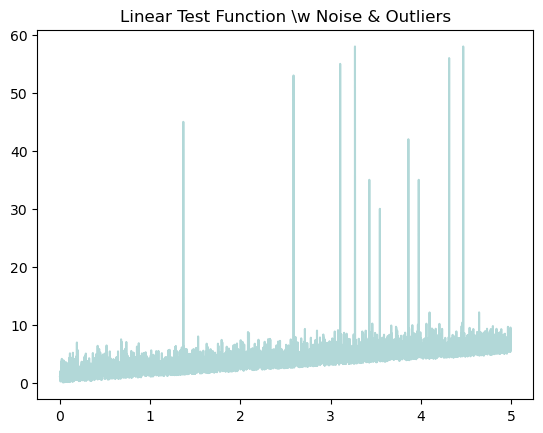

In [13]:
plt.title("Linear Test Function \\w Noise & Outliers")
plt.plot(x, y, color="teal", alpha=0.3)
plt.show()

# Detect with Linear Regression

Run linear regression using `scipy`, which provides the slope, intercept, and standard error. Then use `numpy` to create a function from the coefficients.

In [14]:
def linreg(x, y):
    slope, intercept, rvalue, pvalue, stderr = scipy.stats.linregress(x, y)
    coef = np.array([slope, intercept])
    poly1d_fn = np.poly1d(coef) 
    return poly1d_fn, coef

poly1d_fn, coef = linreg(x, y)

Transform the intercept value to move the linear regression up. Do this until the number of removed outliers does not change much. This might be the optimal confidence bounds such that the number of removed outliers is minimal.

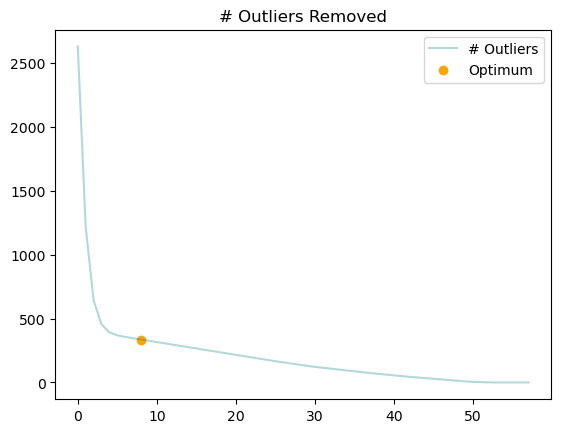

In [15]:
def transform_y(x, y, coef):
    num_outliers = []
    for i in range(0, int(max(y))):
        _coef = coef + np.array([0, i])
        _poly1d_fn = np.poly1d(_coef)
        _y = _poly1d_fn(x)
        _diff = y - _y
        _diff[_diff < 0] = 0
        num_outliers.append(sum(_diff))

    for i in range(2, len(num_outliers)):
        a = num_outliers[i - 2] - num_outliers[i - 1]
        b = num_outliers[i - 1] - num_outliers[i]
        if a / b < 1.1:
            break

    plt.title("# Outliers Removed")
    plt.plot(num_outliers, label="# Outliers", color="teal", alpha=0.3)
    plt.scatter(i, num_outliers[i], label="Optimum", color="orange")
    plt.legend()
    plt.show()

    return i

i = transform_y(x, y , coef)

Now, every value above the transformed upper confidence bounds is called an outlier.

In [16]:
def detect(x, y, coef, y_offset):
    coef = coef + np.array([0, y_offset])
    conf_poly1d_fn = np.poly1d(coef)

    _y = conf_poly1d_fn(x)
    outlier_x = np.where((y - _y) > 0)[0]
    outlier_y = y[outlier_x]
    outlier_x = outlier_x / (len(x) / max(x))
    return outlier_x, outlier_y, conf_poly1d_fn

outlier_x, outlier_y, conf_poly1d_fn = detect(x, y, coef, i)

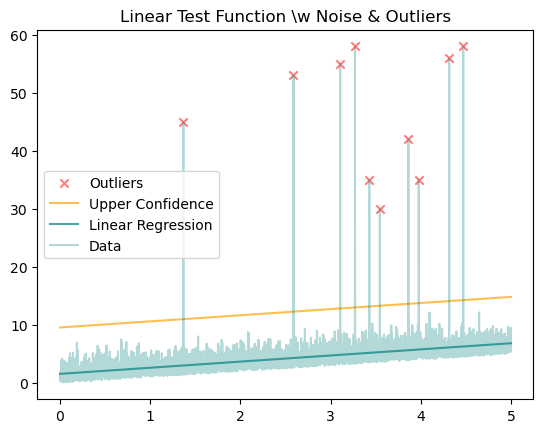

In [17]:
plt.title("Linear Test Function \\w Noise & Outliers")
plt.scatter(outlier_x, outlier_y, alpha=0.5, color="red", marker="x", label="Outliers")
plt.plot(x, conf_poly1d_fn(x), alpha=0.7, color="orange", label="Upper Confidence")
plt.plot(x, poly1d_fn(x), alpha=0.7, color="teal", label="Linear Regression")
plt.plot(x, y, alpha=0.3, color="teal", label="Data")
plt.legend()
plt.show()

Test the linear regression method with automatic upper confidence bounds on a non-linear problem.

In [18]:
x = np.linspace(0, 3, 5_000)
y = (-0.5 *(x - 1.5) ** 2 + 1)*5

noise = np.random.normal(0, 2, len(x))
y += noise

max_val = max(y)
for _ in range(10):
    y[np.random.randint(0, len(y))] = np.random.randint(max_val * 2, max_val * 5)

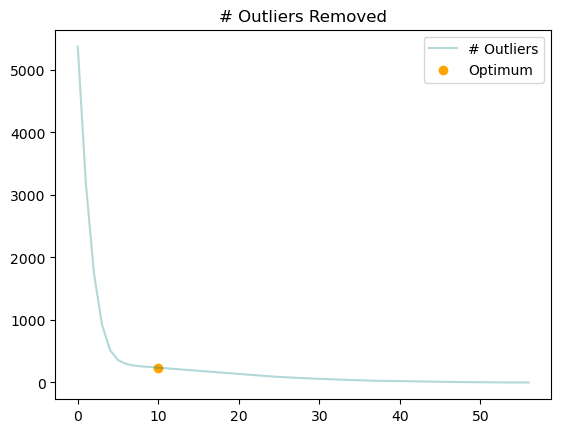

In [19]:
poly1d_fn, coef = linreg(x, y)
y_offset = transform_y(x, y , coef)
outlier_x, outlier_y, conf_poly1d_fn = detect(x, y, coef, y_offset)

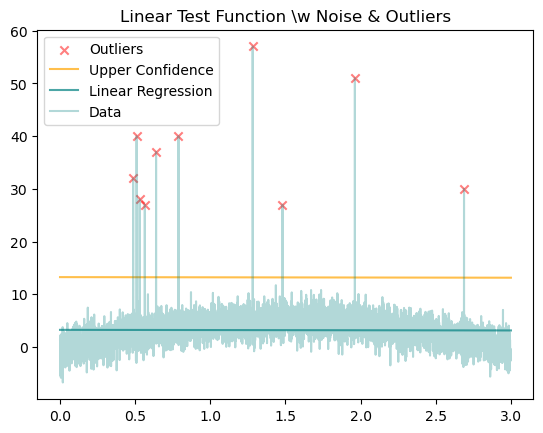

In [20]:
plt.title("Linear Test Function \\w Noise & Outliers")
plt.scatter(outlier_x, outlier_y, alpha=0.5, color="red", marker="x", label="Outliers")
plt.plot(x, conf_poly1d_fn(x), alpha=0.7, color="orange", label="Upper Confidence")
plt.plot(x, poly1d_fn(x), alpha=0.7, color="teal", label="Linear Regression")
plt.plot(x, y, alpha=0.3, color="teal", label="Data")
plt.legend()
plt.show()

# Detect with rolling median

In [22]:
df = pd.DataFrame(y)

array([[<Axes: title={'center': '0'}>]], dtype=object)

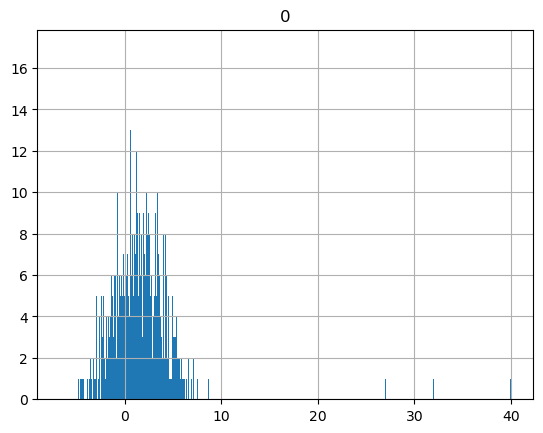

In [30]:
df[:1000].hist(bins=1000)

In [107]:
# Calculate the interquartile range (IQR)
q1 = df.quantile(0.0)
q3 = df.quantile(0.9)
iqr = q3 - q1

# Define a threshold for outliers
threshold = 1.5 * iqr

# Identify the outliers, which are defining the threshold
outliers_x = df[(df < (q1 - threshold)) | (df > (q3 + threshold))].dropna().index.to_numpy(dtype=np.int32)
outlier_y = y[outlier_x.astype(np.int32)]
outliers_x2 = outliers_x.astype(np.float32) / (len(x) / max(x))

In [110]:
outliers_x.astype(np.int32), np.argmax(y)

(array([ 811,  849,  883,  940, 1065, 1313, 2136, 2467, 3269, 4479],
       dtype=int32),
 2136)

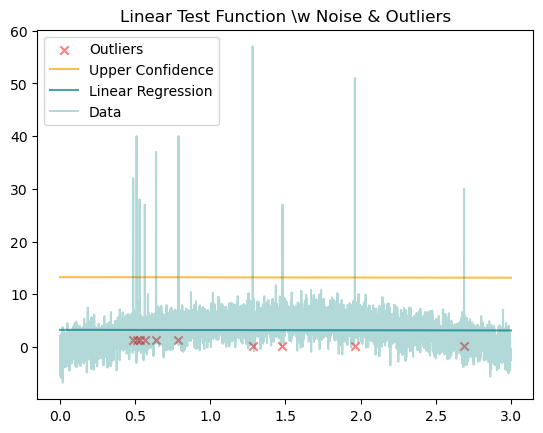

In [109]:
plt.title("Linear Test Function \\w Noise & Outliers")
plt.scatter(outliers_x2, outlier_y, alpha=0.5, color="red", marker="x", label="Outliers")
plt.plot(x, conf_poly1d_fn(x), alpha=0.7, color="orange", label="Upper Confidence")
plt.plot(x, poly1d_fn(x), alpha=0.7, color="teal", label="Linear Regression")
plt.plot(x, y, alpha=0.3, color="teal", label="Data")
plt.legend()
plt.show()